# Logistic Regression Project: Diabetes Prediction using Kaggle Data
**Student:** ____________________  **Date:** ____________

**Objective:** Predict `Outcome` (0 = No diabetes, 1 = Diabetes).
**Dataset:** Pima Indians Diabetes Database (Kaggle) - `diabetes.csv`
**Model:** Median imputation + StandardScaler + balanced Logistic Regression

**Workflow:** load CSV → inspect data → replace invalid zeros → train-test split → median imputation → scaling → train model → evaluate → interpret coefficients

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, classification_report)
sns.set_style('whitegrid')

## 2. Load and Inspect Data

In [2]:
df = pd.read_csv('diabetes.csv')
print('Shape:', df.shape)
df.head()

Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.info()
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


Missing values:
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Class distribution:
 Outcome
0    500
1    268
Name: count, dtype: int64


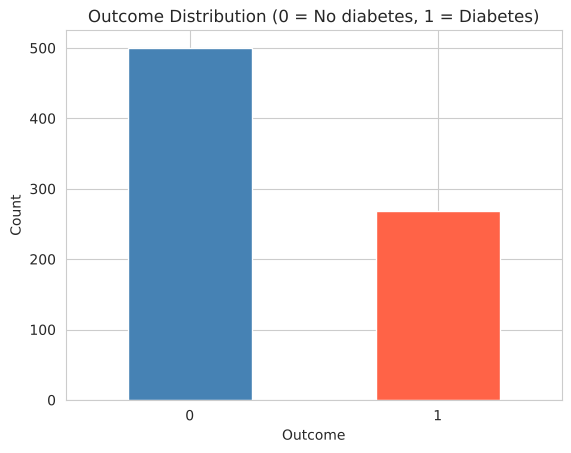

In [4]:
print('Missing values:\n', df.isnull().sum())
print('\nClass distribution:\n', df['Outcome'].value_counts())
df['Outcome'].value_counts().plot(kind='bar', color=['steelblue','tomato'])
plt.title('Outcome Distribution (0 = No diabetes, 1 = Diabetes)')
plt.xticks(rotation=0); plt.ylabel('Count'); plt.show()

## 3. Replace Invalid Zeros
Glucose, BloodPressure, SkinThickness, Insulin and BMI cannot physiologically be 0, so zeros there are treated as missing values (NaN).

In [5]:
zero_cols = ['Glucose','BloodPressure','SkinThickness','Insulin','BMI']
print('Zeros before replacement:\n', (df[zero_cols]==0).sum())
df[zero_cols] = df[zero_cols].replace(0, np.nan)
print('\nMissing values after replacement:\n', df[zero_cols].isnull().sum())

Zeros before replacement:
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Missing values after replacement:
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


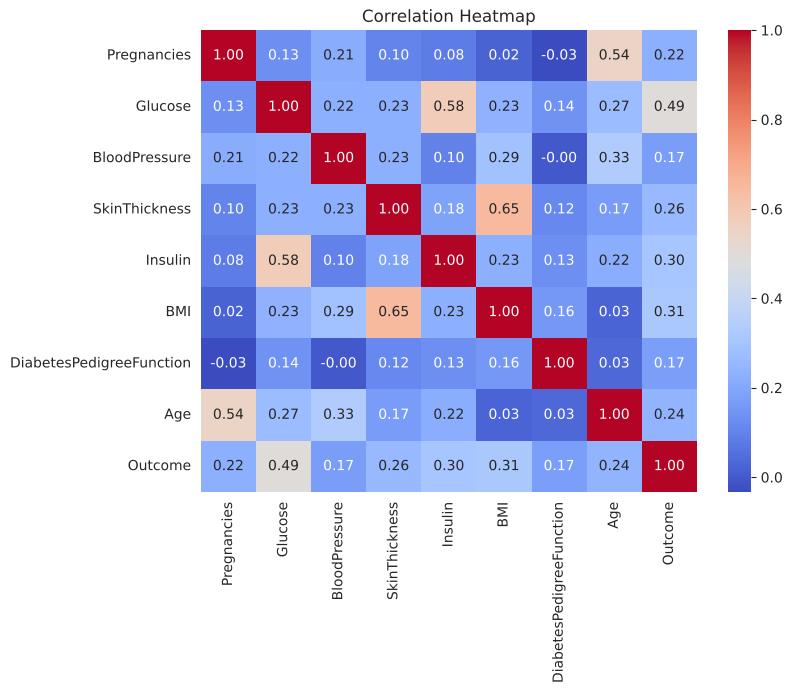

In [6]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap'); plt.show()

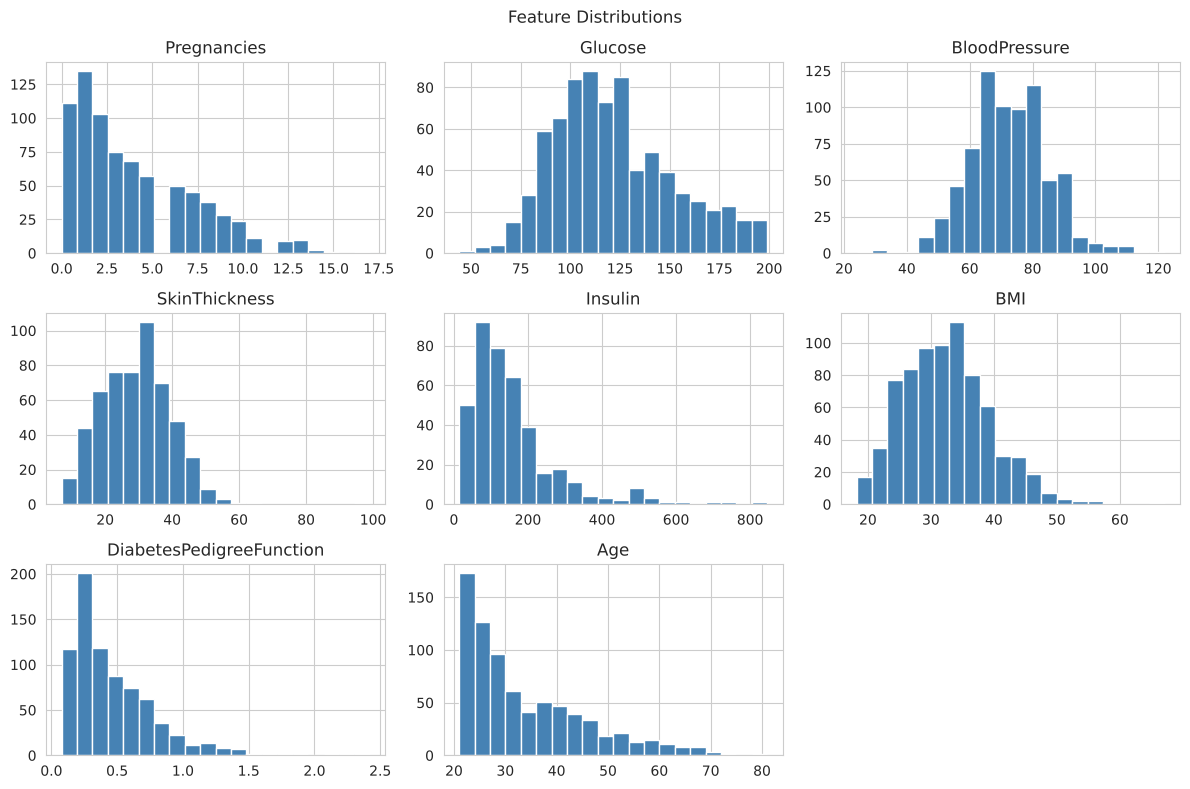

In [7]:
df.drop(columns='Outcome').hist(figsize=(12,8), bins=20, color='steelblue')
plt.suptitle('Feature Distributions'); plt.tight_layout(); plt.show()

## 4. Train-Test Split
Fixed 80/20 stratified split (`random_state=42`). Splitting **before** imputation/scaling avoids data leakage.

In [8]:
X = df.drop(columns='Outcome')
y = df['Outcome']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (614, 8)  Test: (154, 8)


## 5. Build Pipeline: Median Imputation → Scaling → Balanced Logistic Regression

In [9]:
model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])
model.fit(X_train, y_train)
print('Model trained.')

Model trained.


## 6. Evaluation

In [10]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    'Metric': ['Accuracy','Precision','Recall','F1-score','ROC-AUC'],
    'Result': [accuracy_score(y_test,y_pred), precision_score(y_test,y_pred),
               recall_score(y_test,y_pred), f1_score(y_test,y_pred),
               roc_auc_score(y_test,y_prob)],
    'Meaning': ['Overall correct predictions','Reliability of positive predictions',
                'Actual positive cases detected','Balance of precision and recall',
                'Overall class-separation ability']
})
results['Result'] = results['Result'].round(3)
results

,Metric,Result,Meaning
0,Accuracy,0.734,Overall correct predictions
1,Precision,0.603,Reliability of positive predictions
2,Recall,0.704,Actual positive cases detected
3,F1-score,0.650,Balance of precision and recall
4,ROC-AUC,0.813,Overall class-separation ability


In [11]:
print(classification_report(y_test, y_pred, target_names=['No diabetes','Diabetes']))

              precision    recall  f1-score   support

 No diabetes       0.82      0.75      0.79       100
    Diabetes       0.60      0.70      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.72       154
weighted avg       0.75      0.73      0.74       154



### Confusion Matrix

TN = 75, FP = 25, FN = 16, TP = 38


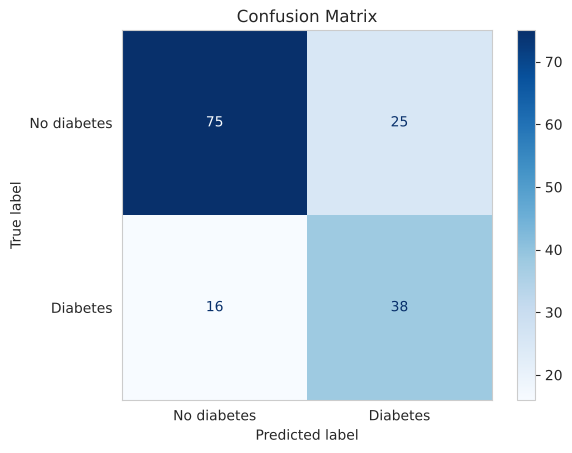

In [12]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f'TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}')
ConfusionMatrixDisplay(cm, display_labels=['No diabetes','Diabetes']).plot(cmap='Blues')
plt.title('Confusion Matrix'); plt.grid(False); plt.show()

### ROC Curve

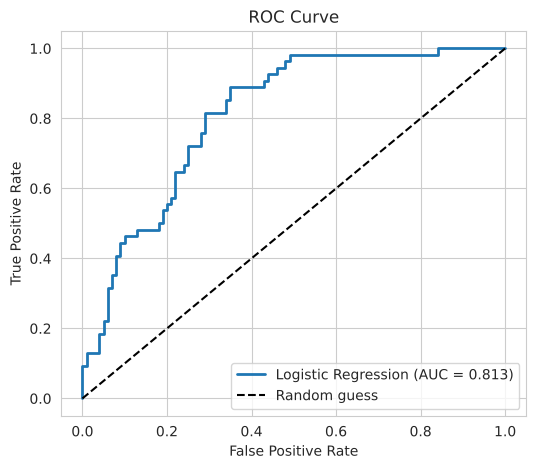

In [13]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test,y_prob):.3f})', lw=2)
plt.plot([0,1],[0,1],'k--', label='Random guess')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curve'); plt.legend(); plt.show()

## 7. Interpret Coefficients
Features were standardized, so coefficients are directly comparable. Positive = increases odds of diabetes.

,Feature,Coefficient,Odds Ratio
0,Glucose,1.183,3.266
1,BMI,0.710,2.033
2,Pregnancies,0.373,1.452
3,DiabetesPedigreeFunction,0.288,1.333
4,Age,0.186,1.205
5,SkinThickness,0.014,1.014
6,BloodPressure,-0.015,0.985
7,Insulin,-0.045,0.956


/tmp/ipykernel_122/3849642710.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef, x='Coefficient', y='Feature', palette='viridis')


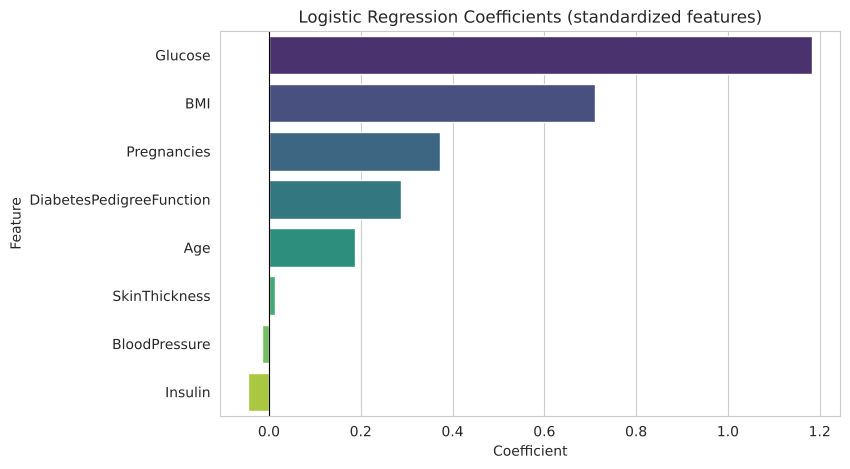

In [14]:
coef = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.named_steps['clf'].coef_[0]
})
coef['Odds Ratio'] = np.exp(coef['Coefficient'])
coef = coef.sort_values('Coefficient', ascending=False).reset_index(drop=True)
display(coef.round(3))

plt.figure(figsize=(8,5))
sns.barplot(data=coef, x='Coefficient', y='Feature', palette='viridis')
plt.axvline(0, color='k', lw=0.8)
plt.title('Logistic Regression Coefficients (standardized features)'); plt.show()

## 8. Key Findings
- The model achieves a **ROC-AUC of about 0.813** and detects approximately **70.4%** of the positive cases in the fixed test split.
- **Glucose** and **BMI** have the strongest positive coefficients.
- **Recall** is especially important in a screening-style task because false negatives are missed positive cases. `class_weight='balanced'` trades some precision for higher recall.

**Limitation:** This small historical dataset represents a specific population (Pima Indian women, 21+ years). The model is suitable for learning classification concepts, **not for medical diagnosis**.

## 9. Conclusion
*(Write your final conclusion in your own words here.)*

Suggested starting points: What did the metrics tell you? Why does recall matter here? What would you try next (e.g., cross-validation, threshold tuning, other models)?